In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/sample_submission.csv
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/classes.csv
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/train.csv
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test.csv
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_00733.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_03144.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_01642.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_00121.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_00739.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_01420.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_01977.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_00432.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_02001.jpg
/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai/test/test_00180.jpg
/kaggle/input/competitions/nppe-1

## Step 1: Import libraries

In [3]:
import os
import glob
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report

## Step 2: Settings

In [4]:
DATA_DIR = os.path.dirname(glob.glob("/kaggle/input/**/train.csv", recursive=True)[0])
OUTPUT_DIR = "/kaggle/working"

IMG_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 150
LR = 1e-3
WEIGHT_DECAY = 0.05
NUM_CLASSES = 20
NUM_WORKERS = os.cpu_count()
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

print(DATA_DIR)
print(device)

/kaggle/input/competitions/nppe-1-26-t-3-dl-gen-ai
cuda


## Step 3: Load the data

In [5]:
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
classes_df = pd.read_csv(f"{DATA_DIR}/classes.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

print(train_df.shape, test_df.shape, sample_sub.shape)
classes_df

(9908, 2) (3325, 1) (3325, 2)


,label,class_name,material,condition
0,0,glass_defect,glass,defect
1,1,glass_no_defect,glass,no_defect
2,2,rubber_defect,rubber,defect
3,3,rubber_no_defect,rubber,no_defect
4,4,hard_plastic_defect,hard_plastic,defect
5,5,hard_plastic_no_defect,hard_plastic,no_defect
6,6,wood_coated_defect,wood_coated,defect
7,7,wood_coated_no_defect,wood_coated,no_defect
8,8,wood_uncoated_defect,wood_uncoated,defect
9,9,wood_uncoated_no_defect,wood_uncoated,no_defect


## Step 4: Explore the data

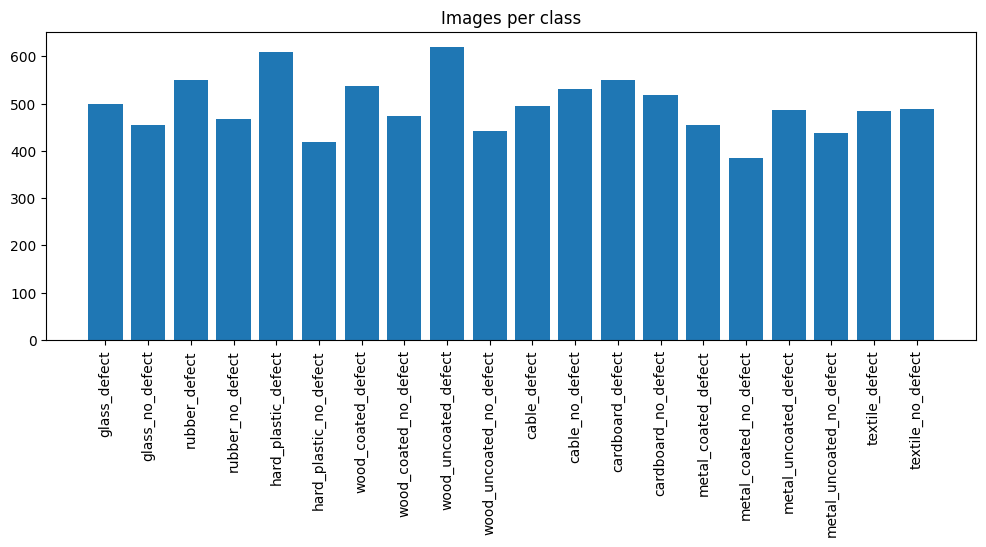

In [6]:
class_names = classes_df["class_name"].tolist()

counts = train_df["label"].value_counts().sort_index()
plt.figure(figsize=(12, 4))
plt.bar(class_names, counts.values)
plt.xticks(rotation=90)
plt.title("Images per class")
plt.show()

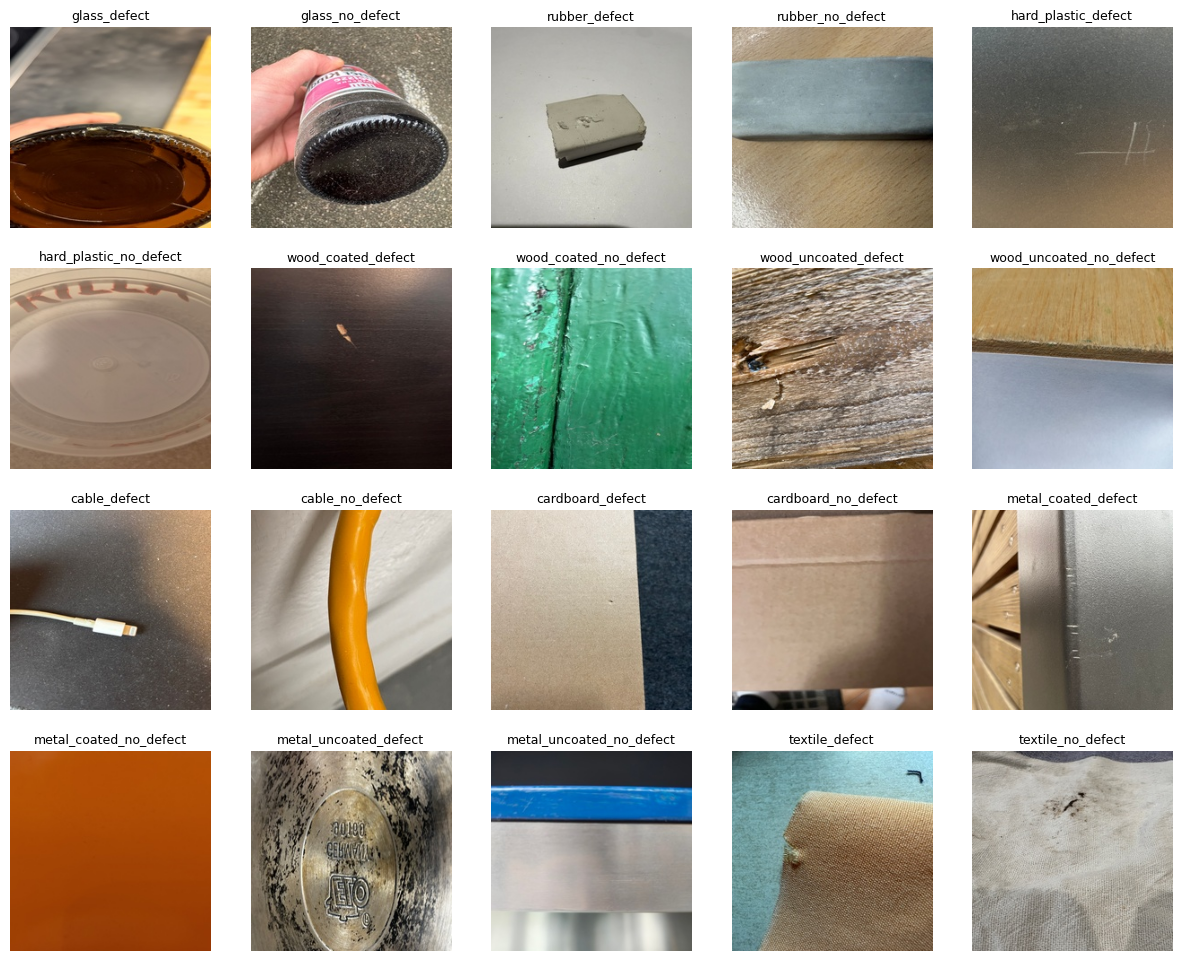

Image size: (224, 224)


In [7]:
plt.figure(figsize=(15, 12))
for label in range(NUM_CLASSES):
    image_id = train_df[train_df["label"] == label]["id"].iloc[0]
    image = Image.open(f"{DATA_DIR}/train/{image_id}.jpg")
    plt.subplot(4, 5, label + 1)
    plt.imshow(image)
    plt.title(class_names[label], fontsize=9)
    plt.axis("off")
plt.show()

print("Image size:", image.size)

## Step 5: Train / validation split

In [8]:
train_part, val_part = train_test_split(train_df, test_size=0.2, stratify=train_df["label"], random_state=SEED)
print(len(train_part), len(val_part))

7926 1982


## Step 6: Dataset and transforms

In [9]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

In [10]:
class SurfaceDataset(Dataset):
    def __init__(self, df, folder, transform):
        self.ids = df["id"].values
        self.labels = df["label"].values
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        image = Image.open(f"{self.folder}/{self.ids[idx]}.jpg").convert("RGB")
        image = self.transform(image)
        return image, self.labels[idx]

## Step 7: DataLoaders

In [11]:
test_df["label"] = -1

train_dataset = SurfaceDataset(train_part, f"{DATA_DIR}/train", train_transform)
val_dataset = SurfaceDataset(val_part, f"{DATA_DIR}/train", test_transform)
test_dataset = SurfaceDataset(test_df, f"{DATA_DIR}/test", test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

images, labels = next(iter(train_loader))
print(images.shape, labels[:10])

torch.Size([64, 3, 224, 224]) tensor([13,  9, 11, 13,  2, 11, 12,  4,  3, 10])


## Step 8: Build the model (from scratch, no pretrained weights)

In [12]:
class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class SurfaceNet(nn.Module):
    def __init__(self, num_classes=20):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, 1, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(3, 2, 1),
        )
        self.layer1 = nn.Sequential(ResBlock(64, 64), ResBlock(64, 64))
        self.layer2 = nn.Sequential(ResBlock(64, 128, 2), ResBlock(128, 128))
        self.layer3 = nn.Sequential(ResBlock(128, 256, 2), ResBlock(256, 256))
        self.layer4 = nn.Sequential(ResBlock(256, 512, 2), ResBlock(512, 512))
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(512 * 2, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        avg = F.adaptive_avg_pool2d(x, 1).flatten(1)
        mx = F.adaptive_max_pool2d(x, 1).flatten(1)
        x = torch.cat([avg, mx], dim=1)
        x = self.dropout(x)
        return self.fc(x)


model = SurfaceNet(NUM_CLASSES)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print(model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE)).shape)

Parameters: 11206964
torch.Size([2, 20])


## Step 9: Training and evaluation functions

In [13]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)


def train_one_epoch(model, loader, optimizer, scheduler, scaler):
    model.train()
    total_loss = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)


def evaluate(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = model(images)
            all_preds.extend(outputs.argmax(1).cpu().numpy())
            all_labels.extend(labels.numpy())
    f1 = f1_score(all_labels, all_preds, average="macro")
    acc = accuracy_score(all_labels, all_preds)
    return f1, acc


def run_training(train_loader, val_loader, epochs, save_path):
    model = SurfaceNet(NUM_CLASSES).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, epochs=epochs, steps_per_epoch=len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history = {"train_loss": [], "val_f1": [], "val_acc": []}
    best_f1 = 0

    for epoch in range(epochs):
        start = time.time()
        train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, scaler)
        val_f1, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_f1"].append(val_f1)
        history["val_acc"].append(val_acc)

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), save_path)

        print(f"Epoch {epoch + 1}/{epochs} | loss {train_loss:.4f} | val acc {val_acc:.4f} | val F1 {val_f1:.4f} | {time.time() - start:.0f}s")

    print("Best val F1:", round(best_f1, 4))
    return history

## Step 10: Check the pipeline on a small subset (2 epochs) 

In [14]:
small_train = train_part.sample(500, random_state=SEED)
small_val = val_part.sample(200, random_state=SEED)

small_train_loader = DataLoader(SurfaceDataset(small_train, f"{DATA_DIR}/train", train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
small_val_loader = DataLoader(SurfaceDataset(small_val, f"{DATA_DIR}/train", test_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

check_history = run_training(small_train_loader, small_val_loader, 2, f"{OUTPUT_DIR}/check_model.pth")

/tmp/ipykernel_49/1262675849.py:17: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch 1/2 | loss 3.7689 | val acc 0.0500 | val F1 0.0048 | 9s
Epoch 2/2 | loss 3.1319 | val acc 0.0500 | val F1 0.0048 | 2s
Best val F1: 0.0048


## Step 11: Full training (best model is saved as a checkpoint)

In [15]:
history = run_training(train_loader, val_loader, EPOCHS, f"{OUTPUT_DIR}/best_model.pth")

/tmp/ipykernel_49/1262675849.py:17: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch 1/150 | loss 3.2848 | val acc 0.1589 | val F1 0.1334 | 27s
Epoch 2/150 | loss 2.9292 | val acc 0.1625 | val F1 0.1247 | 24s
Epoch 3/150 | loss 2.8272 | val acc 0.1781 | val F1 0.1476 | 24s
Epoch 4/150 | loss 2.7456 | val acc 0.1831 | val F1 0.1539 | 24s
Epoch 5/150 | loss 2.7202 | val acc 0.2190 | val F1 0.1934 | 24s
Epoch 6/150 | loss 2.6822 | val acc 0.2175 | val F1 0.1919 | 24s
Epoch 7/150 | loss 2.6681 | val acc 0.2109 | val F1 0.1849 | 24s
Epoch 8/150 | loss 2.6213 | val acc 0.2195 | val F1 0.1970 | 24s
Epoch 9/150 | loss 2.6073 | val acc 0.2255 | val F1 0.1907 | 24s
Epoch 10/150 | loss 2.5552 | val acc 0.2301 | val F1 0.2077 | 24s
Epoch 11/150 | loss 2.5188 | val acc 0.2164 | val F1 0.1942 | 24s
Epoch 12/150 | loss 2.5091 | val acc 0.2346 | val F1 0.2188 | 24s
Epoch 13/150 | loss 2.4849 | val acc 0.2523 | val F1 0.2180 | 24s
Epoch 14/150 | loss 2.4482 | val acc 0.2558 | val F1 0.2254 | 24s
Epoch 15/150 | loss 2.4231 | val acc 0.2740 | val F1 0.2453 | 24s
Epoch 16/150 | loss

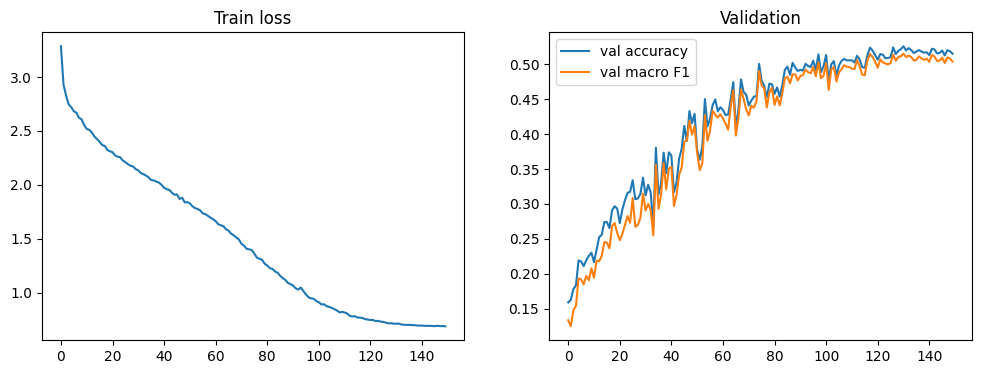

In [16]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"])
plt.title("Train loss")
plt.subplot(1, 2, 2)
plt.plot(history["val_acc"], label="val accuracy")
plt.plot(history["val_f1"], label="val macro F1")
plt.legend()
plt.title("Validation")
plt.show()

## Step 12: Evaluate the best model on validation

In [17]:
def predict(model, loader):
    model.eval()
    all_probs = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                probs = model(images).softmax(1)
                probs += model(torch.flip(images, dims=[3])).softmax(1)
                probs += model(torch.flip(images, dims=[2])).softmax(1)
            all_probs.append(probs.float().cpu())
    return torch.cat(all_probs)


model = SurfaceNet(NUM_CLASSES).to(device)
model.load_state_dict(torch.load(f"{OUTPUT_DIR}/best_model.pth", map_location=device))

val_f1, val_acc = evaluate(model, val_loader)
print("Val macro F1:", round(val_f1, 4))

val_preds = predict(model, val_loader).argmax(1).numpy()
print("Val macro F1 with flips:", round(f1_score(val_part["label"], val_preds, average="macro"), 4))
print(classification_report(val_part["label"], val_preds, target_names=class_names, zero_division=0))

Val macro F1: 0.5151
Val macro F1 with flips: 0.5258
                          precision    recall  f1-score   support

            glass_defect       0.44      0.54      0.49       100
         glass_no_defect       0.56      0.44      0.49        91
           rubber_defect       0.55      0.54      0.54       110
        rubber_no_defect       0.47      0.49      0.48        93
     hard_plastic_defect       0.47      0.56      0.51       122
  hard_plastic_no_defect       0.41      0.38      0.39        84
      wood_coated_defect       0.55      0.56      0.56       108
   wood_coated_no_defect       0.55      0.49      0.52        95
    wood_uncoated_defect       0.62      0.65      0.63       124
 wood_uncoated_no_defect       0.43      0.35      0.39        88
            cable_defect       0.56      0.64      0.60        99
         cable_no_defect       0.65      0.62      0.63       107
        cardboard_defect       0.67      0.65      0.66       110
     cardboard_no_defe

## Step 13: Predict the test images

In [18]:
test_preds = predict(model, test_loader).argmax(1).numpy()
print(len(test_preds))

3325


## Step 14: Create the submission file

In [19]:
submission = pd.DataFrame({"id": test_df["id"], "label": test_preds})
submission.to_csv(f"{OUTPUT_DIR}/submission.csv", index=False)

print(submission.shape)
print("Unique ids:", submission["id"].is_unique)
print("Same ids as sample:", set(submission["id"]) == set(sample_sub["id"]))
print("Label range:", submission["label"].min(), submission["label"].max())
submission.head()

(3325, 2)
Unique ids: True
Same ids as sample: True
Label range: 0 19


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,18
3,test_00004,5
4,test_00005,13
